# 6. Aposentadoria e demografia

A segunda parte do texto conclui que não sobra saída para a aposentadoria:

- a **capitalização** (guardar dinheiro e viver dos rendimentos) seria inviável por causa do juro negativo;
- a **repartição** (os trabalhadores de hoje pagam os aposentados de hoje, como no INSS) seria insustentável por
  causa da queda da natalidade.

Este notebook testa as duas, com os números de investimento dos notebooks anteriores e com dados de população.
As explicações que o texto dá para a queda da natalidade (mudanças de costumes e políticas públicas) não são
testáveis com estas séries e ficam de fora.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from juro_negativo import analise, estilo
from juro_negativo.caminhos import TRATADOS
from juro_negativo.estilo import br, pct

estilo.aplicar()

brasil = pd.read_parquet(TRATADOS / "brasil.parquet")
demografia = pd.read_parquet(TRATADOS / "demografia.parquet").set_index(["pais", "ano"])
niveis = analise.niveis_do_brasil(brasil)
populacao = demografia.loc["BRA"]
FIM = niveis.index[-1] + pd.DateOffset(months=1)

## Capitalização: quem guardou todo mês

A conta é a de alguém que aplica o mesmo valor todo mês, corrigido pela inflação, e nunca saca. O resultado é o
saldo dividido pelo total guardado, tudo em reais de hoje. Acima de 1, o dinheiro rendeu mais que os preços.

Quem fez isso na Selic desde janeiro de 2008 tem 1,52 vez o que guardou. Desde 1995, 2,86 vezes. No Ibovespa,
1,42 e 2,19. No ouro, 3,04 e 5,20.

Pela régua do M2 (corrigindo os aportes e o saldo pelo M2), a Selic e o Ibovespa ficam abaixo de 1, como era de
esperar pelo notebook 2.

In [2]:
linhas = []
for inicio in ["1995-01", "2000-01", "2008-01", "2016-01"]:
    linha = {"começo": f"{inicio[5:]}/{inicio[:4]}"}
    for regua in ("ipca", "m2"):
        for ativo in ("selic", "ibovespa", "ouro"):
            linha[f"{ativo} ÷ {regua}"] = br(analise.poupar_todo_mes(niveis, ativo, regua, inicio, FIM).iloc[-1], 2)
    linhas.append(linha)
pd.DataFrame(linhas).set_index("começo")

,selic ÷ ipca,ibovespa ÷ ipca,ouro ÷ ipca,selic ÷ m2,ibovespa ÷ m2,ouro ÷ m2
começo,,,,,,
01/1995,"2,86","2,19","5,20","0,81","0,70","1,50"
01/2000,"2,02","1,75","4,18","0,76","0,70","1,48"
01/2008,"1,52","1,42","3,04","0,84","0,80","1,55"
01/2016,"1,31","1,38","2,27","0,88","0,92","1,43"


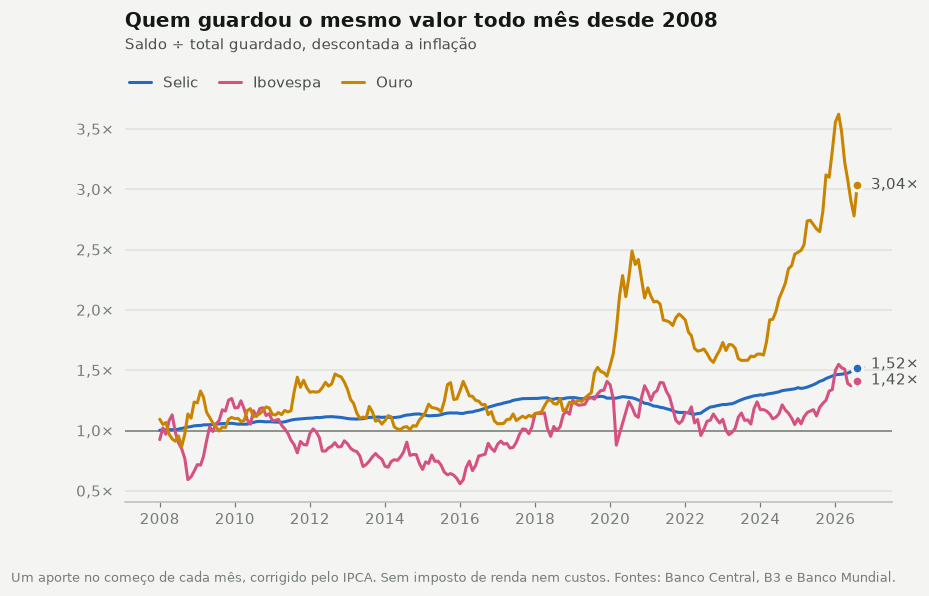

In [3]:
fig, ax = plt.subplots()
for ativo, nome in {"selic": "Selic", "ibovespa": "Ibovespa", "ouro": "Ouro"}.items():
    ax.plot(analise.poupar_todo_mes(niveis, ativo, "ipca", "2008-01", FIM), color=estilo.cor(ativo), label=nome)
estilo.linha_de_base(ax, 1)
estilo.titulo(
    ax, "Quem guardou o mesmo valor todo mês desde 2008", "Saldo ÷ total guardado, descontada a inflação", legenda=True
)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: estilo.vezes(v, 1)))
estilo.rotular_fins(ax, lambda v: estilo.vezes(v))
estilo.fonte(
    fig,
    "Um aporte no começo de cada mês, corrigido pelo IPCA. Sem imposto de renda nem custos. Fontes: Banco Central, B3 e Banco Mundial.",
)
plt.show()

### E o imposto de renda?

O texto lembra, com razão, que o imposto incide sobre o rendimento nominal, inflação incluída. Com 15% sobre todo
o rendimento no resgate (a alíquota de aplicações com mais de dois anos), o ganho da Selic acima da inflação
desde 2008 cai de 4,1% para 3,4% ao ano. Continua positivo.

Para quem começa hoje, a taxa contratada é mais alta do que a média do período: o Tesouro IPCA+ paga 8,2% ao ano
acima da inflação.

In [4]:
v = analise.variacao(niveis, "2008-01", FIM)
meses = analise.meses_entre("2008-01", FIM)
IMPOSTO = 0.15
bruto = analise.anualizar(analise.descontar(v["selic"], v["ipca"]), meses)
liquido = analise.anualizar(analise.descontar(v["selic"] * (1 - IMPOSTO), v["ipca"]), meses)
taxa = brasil.set_index("data")["tesouro_ipca_taxa_aa"].dropna().iloc[-1]
print(
    f"Selic acima da inflação desde 2008: {pct(bruto, 1)} ao ano sem imposto, {pct(liquido, 1)} com {pct(IMPOSTO)} no resgate"
)
print(
    f"Tesouro IPCA+ hoje: {pct(taxa, 1)} ao ano; o dinheiro dobra de valor real em {br(np.log(2) / np.log(1 + taxa), 1)} anos"
)

Selic acima da inflação desde 2008: 4,1% ao ano sem imposto, 3,4% com 15% no resgate
Tesouro IPCA+ hoje: 8,2% ao ano; o dinheiro dobra de valor real em 8,8 anos


## Repartição: os números de população conferem

O texto diz que a fecundidade brasileira caiu abaixo da reposição em 2003, que os nascimentos de 2021 foram os
menores em 27 anos e que há 20,9% menos crianças de 0 a 4 anos do que adultos de 35 a 39.

Os dados confirmam os três:

- a brasileira tem em média 1,61 filho; o número está abaixo de 2,1 (o nível que repõe a população) desde 2002,
  pelas estimativas da ONU;
- os cartórios registraram 2,69 milhões de nascimentos em 2021, o menor número da série até então. Depois caiu
  mais: 2,42 milhões em 2024, 29% abaixo de 2003;
- em 2022 havia 19,5% menos crianças de 0 a 4 anos do que adultos de 35 a 39. Em 2025, 22%.

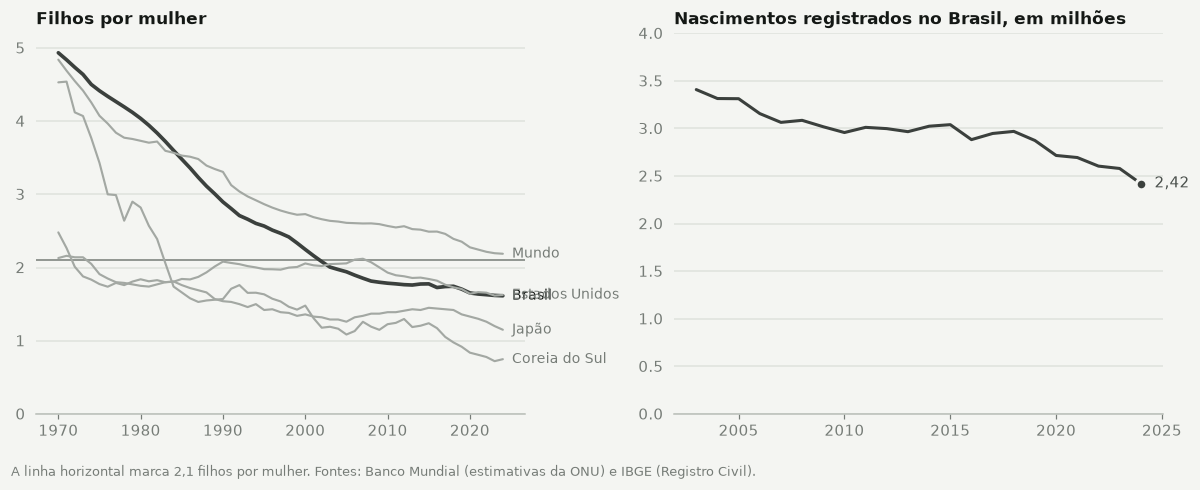

Filhos por mulher em 2024: 1,61; abaixo de 2,1 desde 2002
Nascimentos: 2,69 mi em 2021 (mínimo da série até então: 2021); 2,42 mi em 2024, 29% abaixo de 2003
2022: 13,6 mi de 0 a 4 anos e 16,9 mi de 35 a 39: −19,5%
2025: 12,9 mi de 0 a 4 anos e 16,5 mi de 35 a 39: −22,0%


In [5]:
PAISES = {"BRA": "Brasil", "WLD": "Mundo", "JPN": "Japão", "KOR": "Coreia do Sul", "USA": "Estados Unidos"}
ULTIMO_ANO = 2024  # depois disso a base só traz projeções, de cinco em cinco anos
fecundidade = demografia["fecundidade"].unstack("pais").loc[1970:ULTIMO_ANO, list(PAISES)]

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.2))
ax = eixos[0]
for pais, nome in PAISES.items():
    ax.plot(
        fecundidade[pais],
        color=estilo.GRAFITE if pais == "BRA" else estilo.CINZA,
        lw=2.4 if pais == "BRA" else 1.4,
        label=nome,
    )
estilo.linha_de_base(ax, 2.1)
ax.set_ylim(0, 5.2)
ax.set_title("Filhos por mulher", loc="left", fontsize=11, fontweight="bold")
for pais, nome in PAISES.items():
    ax.annotate(
        nome,
        (ULTIMO_ANO, fecundidade[pais].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=estilo.TINTA if pais == "BRA" else estilo.TINTA_SUAVE,
        annotation_clip=False,
    )

ax = eixos[1]
nascimentos = populacao["nascimentos_registrados"].dropna() / 1e6
ax.plot(nascimentos, color=estilo.GRAFITE, label="Nascimentos")
ax.set_ylim(0, 4)
ax.set_title("Nascimentos registrados no Brasil, em milhões", loc="left", fontsize=11, fontweight="bold")
estilo.rotular_fins(ax, lambda v: br(v, 2))
fig.tight_layout()
estilo.fonte(
    fig,
    "A linha horizontal marca 2,1 filhos por mulher. Fontes: Banco Mundial (estimativas da ONU) e IBGE (Registro Civil).",
)
plt.show()

filhos = populacao["fecundidade"].dropna()
print(
    f"Filhos por mulher em {ULTIMO_ANO}: {br(filhos.loc[ULTIMO_ANO], 2)}; abaixo de 2,1 desde {filhos[filhos < 2.1].index[0]}"
)
print(
    f"Nascimentos: {br(nascimentos[2021], 2)} mi em 2021 (mínimo da série até então: {nascimentos.loc[:2021].idxmin()}); {br(nascimentos.iloc[-1], 2)} mi em {nascimentos.index[-1]}, {pct(1 - nascimentos.iloc[-1] / nascimentos.iloc[0])} abaixo de {nascimentos.index[0]}"
)
for ano in (2022, 2025):
    criancas = populacao.loc[ano, ["idade_0004_homens", "idade_0004_mulheres"]].sum()
    adultos = populacao.loc[ano, ["idade_3539_homens", "idade_3539_mulheres"]].sum()
    print(
        f"{ano}: {br(criancas / 1e6, 1)} mi de 0 a 4 anos e {br(adultos / 1e6, 1)} mi de 35 a 39: {pct(criancas / adultos - 1, 1)}"
    )

## A pirâmide vira

As barras são a população de 2025; o traço, a projeção da ONU para 2050. Embaixo, as faixas de crianças e jovens
encolhem. No alto, as de idosos crescem. A população total chega ao máximo em 2042, com 219 milhões, e passa a
diminuir.

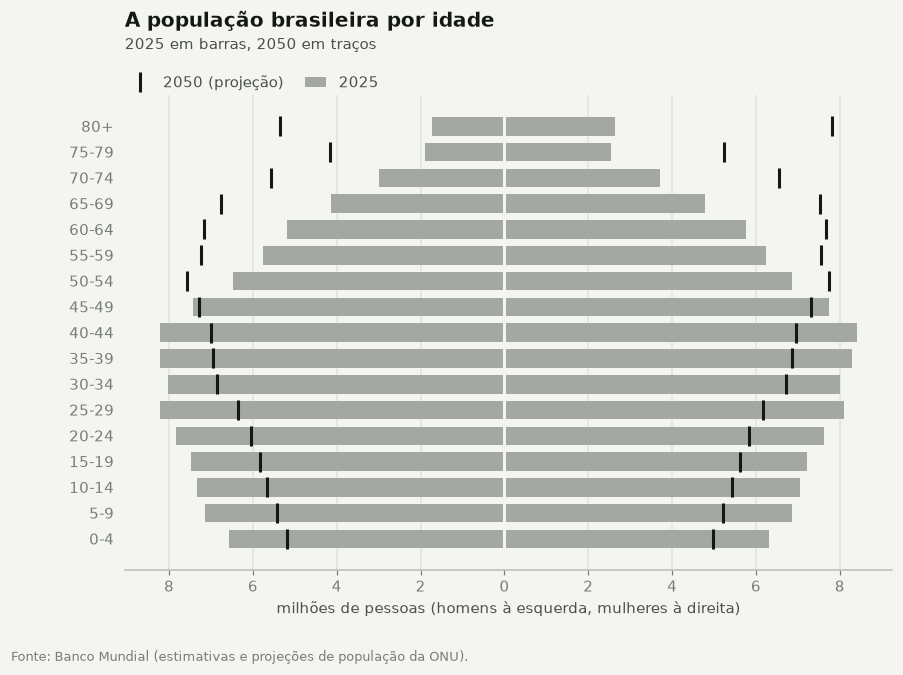

Pico da população: 219,3 milhões em 2042; 217,5 milhões em 2050


In [6]:
faixas = sorted({coluna.split("_")[1] for coluna in populacao.columns if coluna.startswith("idade_")})
rotulos = ["80+" if faixa == "80UP" else f"{int(faixa[:2])}-{int(faixa[2:])}" for faixa in faixas]
posicoes = np.arange(len(faixas))

fig, ax = plt.subplots(figsize=(9, 5.6))
for sexo, sinal in (("homens", -1), ("mulheres", 1)):
    hoje = populacao.loc[2025, [f"idade_{faixa}_{sexo}" for faixa in faixas]].to_numpy() / 1e6
    futuro = populacao.loc[2050, [f"idade_{faixa}_{sexo}" for faixa in faixas]].to_numpy() / 1e6
    ax.barh(posicoes, sinal * hoje, color=estilo.CINZA, height=0.72, label="2025" if sinal > 0 else None)
    ax.plot(
        sinal * futuro, posicoes, "|", color=estilo.TINTA, ms=13, mew=2, label="2050 (projeção)" if sinal > 0 else None
    )
ax.set_yticks(posicoes, rotulos)
ax.set_xticks(np.arange(-8, 9, 2))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(abs(v))))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.axvline(0, color=estilo.SUPERFICIE, lw=2)
ax.set_xlabel("milhões de pessoas (homens à esquerda, mulheres à direita)")
estilo.titulo(ax, "A população brasileira por idade", "2025 em barras, 2050 em traços", legenda=True)
estilo.fonte(fig, "Fonte: Banco Mundial (estimativas e projeções de população da ONU).")
plt.show()

total = populacao["populacao"].dropna()
print(
    f"Pico da população: {br(total.max() / 1e6, 1)} milhões em {total.idxmax()}; {br(total[2050] / 1e6, 1)} milhões em 2050"
)

## Quantos idosos por trabalhador

A medida que interessa para a repartição é a **razão de dependência de idosos**: pessoas de 65 anos ou mais para
cada 100 em idade de trabalhar (15 a 64). No Brasil eram 8 em 2000. São 17 hoje e serão 36 em 2050. O país faz em
50 anos o caminho que a Europa fez em mais de um século.

Um sistema em que quem trabalha paga quem se aposentou fica mais pesado a cada ano. Essa parte do diagnóstico do
texto se sustenta nos dados.

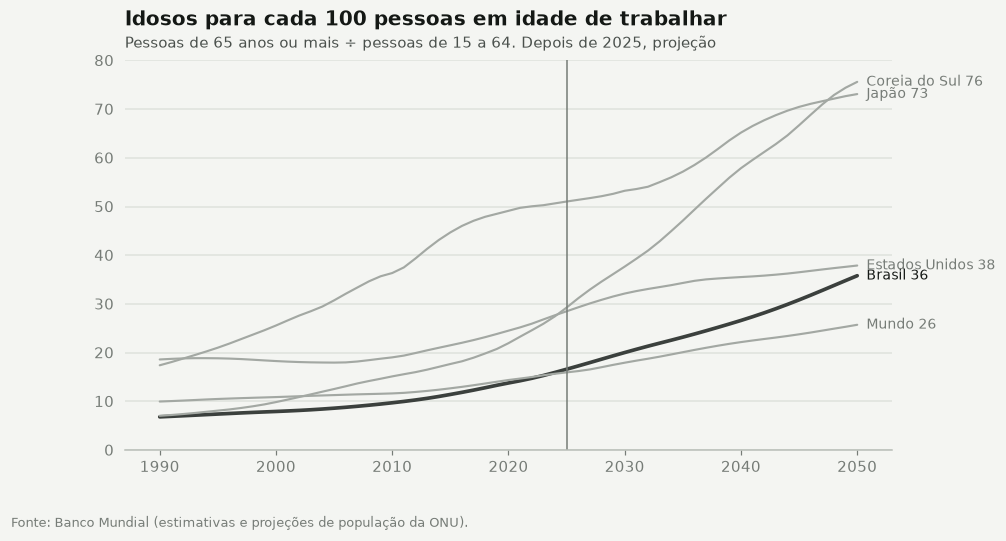

Brasil: 2000: 8, 2025: 17, 2050: 36


In [7]:
PAISES = {"BRA": "Brasil", "WLD": "Mundo", "USA": "Estados Unidos", "JPN": "Japão", "KOR": "Coreia do Sul"}
dependencia = demografia["dependencia_idosos"].unstack("pais").loc[1990:2050, list(PAISES)]

fig, ax = plt.subplots(figsize=(9, 4.6))
for pais, nome in PAISES.items():
    ax.plot(
        dependencia[pais],
        color=estilo.GRAFITE if pais == "BRA" else estilo.CINZA,
        lw=2.4 if pais == "BRA" else 1.4,
        label=nome,
    )
    ax.annotate(
        f"{nome} {br(dependencia[pais].iloc[-1])}",
        (2050, dependencia[pais].iloc[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=estilo.TINTA if pais == "BRA" else estilo.TINTA_SUAVE,
        annotation_clip=False,
    )
ax.axvline(2025, color=estilo.TINTA_SUAVE, lw=1)
estilo.titulo(
    ax,
    "Idosos para cada 100 pessoas em idade de trabalhar",
    "Pessoas de 65 anos ou mais ÷ pessoas de 15 a 64. Depois de 2025, projeção",
)
ax.set_ylim(0, 80)
estilo.fonte(fig, "Fonte: Banco Mundial (estimativas e projeções de população da ONU).")
plt.show()

print("Brasil:", ", ".join(f"{ano}: {br(dependencia.loc[ano, 'BRA'])}" for ano in (2000, 2025, 2050)))

## Um número de passagem: o PIB de 2010 e o de 2022

Para falar em "destruição de riqueza", o texto mostra que o PIB do Brasil era menor em 2022 do que em 2010. O
gráfico citado é do PIB **em dólares correntes**, e nessa medida é verdade: US$ 2,21 trilhões em 2010 e US$ 1,95
trilhão em 2022. A queda é do câmbio (o dólar foi de R$ 1,76 para R$ 5,16), não da produção.

Em reais, descontada a inflação, a economia cresceu 11,5% entre os dois anos, e a renda por pessoa, 2,7%. É uma
década ruim, mas não uma queda. Em 2025 o PIB em dólares já estava acima do de 2010.

In [8]:
economia = populacao.loc[[2010, 2022, 2025], ["pib_dolares", "pib_real", "pib_real_por_pessoa"]]
tabela = pd.DataFrame(
    {
        "PIB em US$ trilhões correntes": (economia["pib_dolares"] / 1e12).map(lambda v: br(v, 2)),
        "PIB real (2010 = 100)": (100 * economia["pib_real"] / economia.loc[2010, "pib_real"]).map(lambda v: br(v, 1)),
        "PIB real por pessoa (2010 = 100)": (
            100 * economia["pib_real_por_pessoa"] / economia.loc[2010, "pib_real_por_pessoa"]
        ).map(lambda v: br(v, 1)),
    }
)
tabela

,PIB em US$ trilhões correntes,PIB real (2010 = 100),PIB real por pessoa (2010 = 100)
ano,,,
2010,"2,21","100,0","100,0"
2022,"1,95","111,5","102,7"
2025,"2,28","121,8","110,9"


## O que fica deste notebook

1. **A capitalização não ficou inviável.** Quem guardou na Selic todo mês desde 2008 tem 1,52 vez o que guardou,
   em valores reais; com imposto, o ganho segue positivo. Hoje o Tesouro IPCA+ paga 8,2% ao ano acima da
   inflação.
2. **Os números de população do texto conferem.** Fecundidade abaixo da reposição desde o começo dos anos 2000,
   nascimentos em queda, população encolhendo a partir da década de 2040.
3. **A repartição vai pesar mais.** A relação entre idosos e pessoas em idade de trabalhar dobra de 2025 a 2050.
4. **O que não se sustenta é a conclusão de que não há saída.** A previdência pública fica mais cara, e isso os
   dados confirmam. Guardar por conta própria, com juro real positivo, continua possível.
5. **O PIB "menor em 2022 do que em 2010" é verdade só em dólares.** Em termos reais a economia cresceu 11,5%.